# Stage 8 – DGI-GCN Graph-Based Adversarial Detection

**Research:** *An Unsupervised Graph-Based Framework for Adversarial Attack Detection and Severity Estimation in Deep Learning-Based Alzheimer’s MRI Classification.*

## Purpose
This stage computes graph-aware embeddings for the corrected Stage 7 adversarial examples, calculates anomaly scores using the manuscript's centroid-distance formulation, and evaluates binary detection.

\[
S_i=\|h_i-\mu\|_2,\qquad \widehat{y}_i =
\begin{cases}
1 & S_i>\tau\\
0 & S_i\leq\tau
\end{cases}
\]

where \(h_i\) is the graph embedding, \(\mu\) is the centroid of clean training graph embeddings, and the manuscript specifies \(\tau=0.4\).

## Important methodological decisions
1. The Stage 6 GCN-DGI checkpoint is frozen; Stage 8 does not retrain it.
2. Stage 7 attacks are generated only for images correctly classified by the clean Stage 4 CNN.
3. Adversarial image embeddings are extracted using the **same frozen Stage 4 CNN**.
4. Each adversarial node is attached to its 10 most cosine-similar clean graph nodes. A frozen-graph, one-way extension is used: original clean node representations are not changed by adding attack nodes. This is an explicit inference choice because the original Stage 6 model was trained on the fixed 6,400-node transductive graph.
5. The centroid is calculated using clean **training** graph embeddings only. Test labels are not used to fit the centroid or threshold.
6. The threshold 0.4 is tested exactly as stated in the manuscript. The notebook also reports clean-score distributions so an unsuitable threshold is visible rather than silently changed.
7. The Stage 7 `attack_success` flag is used to identify successful adversarial examples for detection evaluation. Failed CW cases are retained in the score output but are not counted as positive adversarial detections.

**Transductive limitation:** Stage 5/6 used all 6,400 clean image features and graph structure during unsupervised representation learning. This Stage 8 procedure therefore remains connected to the earlier transductive protocol. Do not describe it as a fully independent inductive test.

### Files required
Upload these four ZIP files:
- `Stage4_CNN_Outputs.zip`
- `Stage5_Graph_Outputs.zip`
- `Stage6_DGI_Outputs.zip`
- `Stage7_Final_Corrected_Outputs.zip`

Do not upload the individual `.npz` files one by one if you have the complete Stage 7 ZIP.


## 1. Set up the Colab environment
Run this cell first. A GPU is recommended for CNN feature extraction.

In [1]:
import os, glob, json, zipfile, random, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    average_precision_score
)
from sklearn.neighbors import NearestNeighbors

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
import scipy
print("SciPy:", scipy.__version__)
print("Device:", DEVICE)


PyTorch: 2.11.0+cpu
SciPy: 1.16.3
Device: cpu


## 2. Upload the four required ZIP files
Select all four ZIP files together. If they are already present in the Colab session, you can skip the upload dialog and set `uploaded` to the existing filenames.

In [2]:
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))


Saving Stage4_CNN_Outputs.zip to Stage4_CNN_Outputs.zip
Saving Stage5_Graph_Outputs.zip to Stage5_Graph_Outputs.zip
Saving Stage6_DGI_Outputs.zip to Stage6_DGI_Outputs.zip
Saving Stage7_Final_Corrected_Outputs.zip to Stage7_Final_Corrected_Outputs.zip
Uploaded: ['Stage4_CNN_Outputs.zip', 'Stage5_Graph_Outputs.zip', 'Stage6_DGI_Outputs.zip', 'Stage7_Final_Corrected_Outputs.zip']


## 3. Extract the ZIP files and locate the required outputs

In [3]:
WORK = Path("/content/stage8_work")
WORK.mkdir(parents=True, exist_ok=True)

def safe_extract(zip_path, out_dir):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            target = (out_dir / member.filename).resolve()
            if not str(target).startswith(str(out_dir.resolve())):
                raise ValueError("Unsafe path detected in ZIP.")
        zf.extractall(out_dir)

def uploaded_zip(keyword):
    matches = [name for name in uploaded if name.lower().endswith(".zip") and keyword.lower() in name.lower()]
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected exactly one uploaded ZIP containing '{keyword}'. Found: {matches}")
    return matches[0]

ZIP_DIRS = {}
for key in ["Stage4", "Stage5", "Stage6", "Stage7"]:
    zname = uploaded_zip(key)
    dest = WORK / key.lower()
    safe_extract(zname, dest)
    ZIP_DIRS[key] = dest
    print(f"\\n{key}: {zname}")
    for p in sorted(dest.rglob("*")):
        if p.is_file():
            print(" ", p.relative_to(dest))


\nStage4: Stage4_CNN_Outputs.zip
  best_alzheimer_cnn.pth
  cnn_embedding_manifest.csv
  cnn_embeddings_128d.npz
  cnn_test_class_metrics.csv
  cnn_test_confusion_matrix.csv
  cnn_training_history.csv
  stage4_config_and_metrics.json
\nStage5: Stage5_Graph_Outputs.zip
  cosine_knn_adjacency.npz
  cosine_knn_edges_directed.csv
  graph_construction_config.json
  graph_node_features_and_masks.npz
  graph_node_manifest.csv
\nStage6: Stage6_DGI_Outputs.zip
  stage6_dgi_config.json
  stage6_dgi_gcn_model.pt
  stage6_dgi_graph_embeddings.npz
  stage6_dgi_training_history.csv
\nStage7: Stage7_Final_Corrected_Outputs.zip
  stage7_clean_classifier_summary.csv
  stage7_constraint_checks.csv
  stage7_final_attack_summary.csv
  stage7_final_config.json
  test_CW_L2_correct_only.npz
  test_FGSM_correct_only.npz
  test_PGD_correct_only.npz
  train_CW_L2_correct_only.npz
  train_FGSM_correct_only.npz
  train_PGD_correct_only.npz
  validation_CW_L2_correct_only.npz
  validation_FGSM_correct_only.npz
  

## 4. Load Stage 4 CNN embeddings and checkpoint

In [4]:
def find_one(root, filename):
    found = list(Path(root).rglob(filename))
    if len(found) != 1:
        raise FileNotFoundError(f"Expected one {filename} under {root}; found {len(found)}")
    return found[0]

emb_path = find_one(ZIP_DIRS["Stage4"], "cnn_embeddings_128d.npz")
cnn_ckpt_path = find_one(ZIP_DIRS["Stage4"], "best_alzheimer_cnn.pth")
with np.load(emb_path, allow_pickle=False) as z:
    emb_data = {k: z[k] for k in z.files}

required_keys = [
    "train_embeddings", "validation_embeddings", "test_embeddings",
    "train_indices", "validation_indices", "test_indices"
]
missing = [k for k in required_keys if k not in emb_data]
if missing:
    raise KeyError(f"Missing Stage 4 embedding keys: {missing}")

idx_train = emb_data["train_indices"].astype(np.int64)
idx_val = emb_data["validation_indices"].astype(np.int64)
idx_test = emb_data["test_indices"].astype(np.int64)

N = len(idx_train) + len(idx_val) + len(idx_test)
X_clean = np.zeros((N, 128), dtype=np.float32)
X_clean[idx_train] = emb_data["train_embeddings"].astype(np.float32)
X_clean[idx_val] = emb_data["validation_embeddings"].astype(np.float32)
X_clean[idx_test] = emb_data["test_embeddings"].astype(np.float32)

assert N == 6400 and X_clean.shape == (6400, 128)
assert len(np.unique(np.concatenate([idx_train, idx_val, idx_test]))) == N
assert np.isfinite(X_clean).all()
print("Clean CNN feature matrix:", X_clean.shape)
print("Split counts:", len(idx_train), len(idx_val), len(idx_test))

class AlzheimerCNN(nn.Module):
    def __init__(self, num_classes=4, embedding_dim=128, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2)
        )
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.embedding = nn.Linear(256, embedding_dim)
        self.embedding_activation = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout)
        self.classifier = nn.Linear(embedding_dim, num_classes)
    def forward(self, x, return_embedding=False):
        x = self.features(x)
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        z = self.embedding_activation(self.embedding(x))
        logits = self.classifier(self.dropout(z))
        return (logits, z) if return_embedding else logits

cnn_checkpoint = torch.load(cnn_ckpt_path, map_location=DEVICE, weights_only=False)
class_names = cnn_checkpoint.get("class_names", ["Mild Demented", "Moderate Demented", "Non-Demented", "Very Mild Demented"])
cnn = AlzheimerCNN(num_classes=len(class_names)).to(DEVICE)
cnn.load_state_dict(cnn_checkpoint["model_state_dict"])
cnn.eval()
print("Loaded Stage 4 CNN checkpoint from epoch:", cnn_checkpoint.get("epoch"))


Clean CNN feature matrix: (6400, 128)
Split counts: 4480 960 960
Loaded Stage 4 CNN checkpoint from epoch: 49


## 5. Load the Stage 5 graph and recreate the GCN normalization

In [5]:
adj_path = find_one(ZIP_DIRS["Stage5"], "cosine_knn_adjacency.npz")
A = sp.load_npz(adj_path).tocsr().astype(np.float32)
assert A.shape == (N, N)
assert (A - A.T).nnz == 0
assert np.all(A.data >= 0) and np.isfinite(A.data).all()

A_hat = (A + sp.eye(N, dtype=np.float32, format="csr")).tocsr()
degree = np.asarray(A_hat.sum(axis=1)).ravel().astype(np.float32)
d_inv_sqrt = np.power(degree, -0.5)
D_inv_sqrt = sp.diags(d_inv_sqrt)
A_norm = (D_inv_sqrt @ A_hat @ D_inv_sqrt).tocsr().astype(np.float32)

def scipy_to_torch_sparse(matrix, device):
    coo = matrix.tocoo()
    indices = torch.tensor(np.vstack([coo.row, coo.col]), dtype=torch.long, device=device)
    values = torch.tensor(coo.data, dtype=torch.float32, device=device)
    return torch.sparse_coo_tensor(indices, values, coo.shape, device=device).coalesce()

A_torch = scipy_to_torch_sparse(A_norm, DEVICE)
X_torch = torch.tensor(X_clean, dtype=torch.float32, device=DEVICE)
print("Graph:", A.shape, "| undirected edges:", A.nnz // 2)
print("Degree range with self-loops:", float(degree.min()), float(degree.max()))


Graph: (6400, 6400) | undirected edges: 43681
Degree range with self-loops: 10.409370422363281 30.994962692260742


/tmp/ipykernel_3150/2714831749.py:17: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  return torch.sparse_coo_tensor(indices, values, coo.shape, device=device).coalesce()


## 6. Load the frozen Stage 6 GCN-DGI encoder and verify clean embeddings

In [6]:
class GraphConvolution(nn.Module):
    def __init__(self, in_features, out_features, bias=True):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(in_features, out_features))
        nn.init.xavier_uniform_(self.weight)
        self.bias = nn.Parameter(torch.zeros(out_features)) if bias else None
    def forward(self, x, adj):
        support = torch.matmul(x, self.weight)
        out = torch.sparse.mm(adj, support)
        if self.bias is not None:
            out = out + self.bias
        return out

class GCNEncoder(nn.Module):
    def __init__(self, in_dim=128, hidden_dim=128, dropout=0.5):
        super().__init__()
        self.gc1 = GraphConvolution(in_dim, hidden_dim)
        self.gc2 = GraphConvolution(hidden_dim, hidden_dim)
        self.dropout = dropout
    def forward(self, x, adj):
        h = F.relu(self.gc1(x, adj))
        h = F.dropout(h, p=self.dropout, training=self.training)
        return self.gc2(h, adj)

gcn_path = find_one(ZIP_DIRS["Stage6"], "stage6_dgi_gcn_model.pt")
dgi_path = find_one(ZIP_DIRS["Stage6"], "stage6_dgi_graph_embeddings.npz")
gcn = GCNEncoder().to(DEVICE)
dgi_state = torch.load(gcn_path, map_location=DEVICE, weights_only=True)
# Stage 6 saved the full DGI model; extract only the encoder parameters.
encoder_state = {k.replace("encoder.", "", 1): v for k, v in dgi_state.items() if k.startswith("encoder.")}
if not encoder_state:
    raise KeyError("No encoder.* parameters found in the Stage 6 DGI checkpoint.")
gcn.load_state_dict(encoder_state, strict=True)
gcn.eval()

with np.load(dgi_path, allow_pickle=False) as z:
    H_stage6 = z["graph_embeddings"].astype(np.float32)
    stage6_train_idx = z["train_indices"].astype(np.int64)
    stage6_val_idx = z["val_indices"].astype(np.int64)
    stage6_test_idx = z["test_indices"].astype(np.int64)

assert H_stage6.shape == (N, 128)
assert np.array_equal(idx_train, stage6_train_idx)
assert np.array_equal(idx_val, stage6_val_idx)
assert np.array_equal(idx_test, stage6_test_idx)

with torch.no_grad():
    H_recomputed = gcn(X_torch, A_torch).cpu().numpy()

max_abs_diff = float(np.max(np.abs(H_recomputed - H_stage6)))
print("Maximum absolute difference from saved Stage 6 graph embeddings:", max_abs_diff)
assert max_abs_diff < 1e-4, "Recomputed embeddings do not match Stage 6. Stop and share this output."
print("Stage 6 encoder and graph embeddings verified.")


Maximum absolute difference from saved Stage 6 graph embeddings: 2.384185791015625e-07
Stage 6 encoder and graph embeddings verified.


## 7. Calculate the clean training centroid and inspect the manuscript threshold

The centroid is fitted only on clean training graph embeddings:

\[
\mu=\frac{1}{N_{\mathrm{train}}}\sum_{i\in\mathrm{train}}h_i
\]

The manuscript threshold is kept at 0.4 for this first evaluation. This cell checks whether that value is compatible with the actual Stage 6 embedding scale.


In [7]:
TAU_MANUSCRIPT = 0.4
mu_clean_train = H_stage6[idx_train].mean(axis=0)
clean_train_scores = np.linalg.norm(H_stage6[idx_train] - mu_clean_train, axis=1)
clean_val_scores = np.linalg.norm(H_stage6[idx_val] - mu_clean_train, axis=1)
clean_test_scores = np.linalg.norm(H_stage6[idx_test] - mu_clean_train, axis=1)

def describe_scores(values, name):
    q = np.quantile(values, [0, .05, .25, .50, .75, .90, .95, .99, 1])
    print(name, "n=", len(values), "mean=", round(float(np.mean(values)), 5))
    print("  min, p05, p25, median, p75, p90, p95, p99, max:", np.round(q, 5))
    print("  fraction above manuscript tau=0.4:", round(float(np.mean(values > TAU_MANUSCRIPT)), 5))

describe_scores(clean_train_scores, "Clean train")
describe_scores(clean_val_scores, "Clean validation")
describe_scores(clean_test_scores, "Clean test")

threshold_diagnostic = pd.DataFrame([
    {"split":"train_clean", "n":len(clean_train_scores), "mean_score":clean_train_scores.mean(),
     "median_score":np.median(clean_train_scores), "p95_score":np.quantile(clean_train_scores,.95),
     "fraction_flagged_at_0.4":np.mean(clean_train_scores > TAU_MANUSCRIPT)},
    {"split":"validation_clean", "n":len(clean_val_scores), "mean_score":clean_val_scores.mean(),
     "median_score":np.median(clean_val_scores), "p95_score":np.quantile(clean_val_scores,.95),
     "fraction_flagged_at_0.4":np.mean(clean_val_scores > TAU_MANUSCRIPT)},
    {"split":"test_clean", "n":len(clean_test_scores), "mean_score":clean_test_scores.mean(),
     "median_score":np.median(clean_test_scores), "p95_score":np.quantile(clean_test_scores,.95),
     "fraction_flagged_at_0.4":np.mean(clean_test_scores > TAU_MANUSCRIPT)}
])
display(threshold_diagnostic)


Clean train n= 4480 mean= 1.86115
  min, p05, p25, median, p75, p90, p95, p99, max: [0.9702  1.14976 1.29572 1.55959 2.2745  2.93377 3.37554 4.22672 5.8853 ]
  fraction above manuscript tau=0.4: 1.0
Clean validation n= 960 mean= 1.84663
  min, p05, p25, median, p75, p90, p95, p99, max: [0.98152 1.12312 1.29499 1.5726  2.17549 2.90736 3.4662  4.38306 5.16383]
  fraction above manuscript tau=0.4: 1.0
Clean test n= 960 mean= 1.80353
  min, p05, p25, median, p75, p90, p95, p99, max: [0.96474 1.11487 1.27714 1.53486 2.14487 2.8626  3.31748 3.94239 6.30969]
  fraction above manuscript tau=0.4: 1.0


,split,n,mean_score,median_score,p95_score,fraction_flagged_at_0.4
0,train_clean,4480,1.861155,1.559586,3.375544,1.0
1,validation_clean,960,1.846630,1.572602,3.466197,1.0
2,test_clean,960,1.803529,1.534857,3.317476,1.0


## 8. Define a frozen-graph extension for adversarial nodes

The Stage 6 GCN encoder was trained on the original 6,400-node graph. To obtain graph embeddings for adversarial images without changing the clean reference embeddings, each adversarial CNN feature is connected to its 10 most cosine-similar clean nodes.

For a new node \(v\), the normalized weight to clean node \(i\) is:

\[
\alpha_{vi}=\frac{w_{vi}}{\sqrt{d_vd_i}},\qquad
\alpha_{vv}=\frac{1}{d_v},\qquad d_v=1+\sum_iw_{vi}.
\]

The same two trained GCN layers are then applied to the new node. Original clean node degrees and representations remain frozen. This is an explicit out-of-sample extension of the trained encoder, not a retraining step.


In [8]:
K_NEIGHBORS = 10
X_unit = X_clean / np.maximum(np.linalg.norm(X_clean, axis=1, keepdims=True), 1e-12)
knn = NearestNeighbors(n_neighbors=K_NEIGHBORS, metric="cosine", algorithm="brute", n_jobs=-1)
knn.fit(X_unit)

# Precompute first-layer hidden representations of the original clean graph.
with torch.no_grad():
    W1 = gcn.gc1.weight
    b1 = gcn.gc1.bias
    W2 = gcn.gc2.weight
    b2 = gcn.gc2.bias
    clean_support1 = X_torch @ W1
    H1_clean = F.relu(torch.sparse.mm(A_torch, clean_support1) + b1)
    clean_support2 = H1_clean @ W2

def embed_new_cnn_features(new_features, batch_size=128):
    new_features = np.asarray(new_features, dtype=np.float32)
    if new_features.ndim != 2 or new_features.shape[1] != 128:
        raise ValueError(f"Expected [n,128] CNN features; got {new_features.shape}")
    if not np.isfinite(new_features).all():
        raise ValueError("Non-finite adversarial CNN features found.")
    new_unit = new_features / np.maximum(np.linalg.norm(new_features, axis=1, keepdims=True), 1e-12)
    distances, neighbor_ids = knn.kneighbors(new_unit)
    similarities = np.clip(1.0 - distances, 0.0, 1.0).astype(np.float32)

    out = []
    with torch.no_grad():
        for start in range(0, len(new_features), batch_size):
            end = min(start + batch_size, len(new_features))
            q = torch.tensor(new_features[start:end], dtype=torch.float32, device=DEVICE)
            nbr = torch.tensor(neighbor_ids[start:end], dtype=torch.long, device=DEVICE)
            sim = torch.tensor(similarities[start:end], dtype=torch.float32, device=DEVICE)

            d_new = 1.0 + sim.sum(dim=1)
            d_old = torch.tensor(degree, dtype=torch.float32, device=DEVICE)[nbr]
            alpha_old = sim / torch.sqrt(d_new[:, None] * d_old)
            alpha_self = 1.0 / d_new

            # GCN layer 1: aggregate projected new-node and clean-neighbour features.
            q_support1 = q @ W1
            nbr_support1 = clean_support1[nbr]
            h1_new = alpha_self[:, None] * q_support1 + (alpha_old[:, :, None] * nbr_support1).sum(dim=1) + b1
            h1_new = F.relu(h1_new)

            # GCN layer 2: aggregate first-layer representations with the same frozen-graph extension.
            q_support2 = h1_new @ W2
            nbr_support2 = clean_support2[nbr]
            h2_new = alpha_self[:, None] * q_support2 + (alpha_old[:, :, None] * nbr_support2).sum(dim=1) + b2
            out.append(h2_new.cpu().numpy().astype(np.float32))
    return np.concatenate(out, axis=0) if out else np.empty((0,128), dtype=np.float32)

print("Frozen graph extension ready. k =", K_NEIGHBORS)


Frozen graph extension ready. k = 10


## 9. Load the Stage 7 corrected attack arrays and extract adversarial CNN embeddings
The Stage 7 ZIP must contain `train_FGSM_correct_only.npz`, `validation_FGSM_correct_only.npz`, etc. This stage checks each file's indices, labels and attack-success flags.

In [9]:
ATTACK_NAMES = ["FGSM", "PGD", "CW_L2"]
SPLIT_NAMES = ["train", "validation", "test"]
attack_records = []

for split in SPLIT_NAMES:
    for attack in ATTACK_NAMES:
        fname = f"{split}_{attack}_correct_only.npz"
        p = find_one(ZIP_DIRS["Stage7"], fname)
        with np.load(p, allow_pickle=False) as z:
            rec = {k: z[k] for k in z.files}
        required = ["indices", "adversarial_images", "labels", "clean_predictions",
                    "adversarial_predictions", "attack_success"]
        missing = [k for k in required if k not in rec]
        if missing:
            raise KeyError(f"{fname} missing keys: {missing}")
        n = len(rec["indices"])
        assert rec["adversarial_images"].shape == (n,1,128,128)
        assert np.isfinite(rec["adversarial_images"]).all()
        assert rec["adversarial_images"].min() >= -1e-6 and rec["adversarial_images"].max() <= 1+1e-6
        assert np.array_equal(rec["attack_success"], rec["adversarial_predictions"] != rec["labels"])
        expected_split = {"train":idx_train, "validation":idx_val, "test":idx_test}[split]
        assert np.isin(rec["indices"], expected_split).all(), f"{fname}: indices outside {split} split"
        assert len(np.unique(rec["indices"])) == n, f"{fname}: duplicate indices"
        attack_records.append((split, attack, rec, p))
        print(split, attack, "| n =", n, "| successful =", int(rec["attack_success"].sum()))


train FGSM | n = 4303 | successful = 4301
train PGD | n = 4303 | successful = 4303
train CW_L2 | n = 4303 | successful = 4303
validation FGSM | n = 798 | successful = 797
validation PGD | n = 798 | successful = 797
validation CW_L2 | n = 798 | successful = 798
test FGSM | n = 793 | successful = 793
test PGD | n = 793 | successful = 793
test CW_L2 | n = 793 | successful = 793


## 10. Extract Stage 4 CNN embeddings for the adversarial images

In [10]:
def extract_cnn_embeddings(images, batch_size=64):
    images = np.asarray(images, dtype=np.float32)
    outputs = []
    cnn.eval()
    with torch.no_grad():
        for start in range(0, len(images), batch_size):
            xb = torch.tensor(images[start:start+batch_size], dtype=torch.float32, device=DEVICE)
            logits, z = cnn(xb, return_embedding=True)
            outputs.append(z.cpu().numpy().astype(np.float32))
    return np.concatenate(outputs, axis=0) if outputs else np.empty((0,128), dtype=np.float32)

for split, attack, rec, path in attack_records:
    t0 = time.time()
    rec["adversarial_cnn_embeddings"] = extract_cnn_embeddings(rec["adversarial_images"])
    rec["adversarial_graph_embeddings"] = embed_new_cnn_features(rec["adversarial_cnn_embeddings"])
    assert rec["adversarial_graph_embeddings"].shape == (len(rec["indices"]),128)
    print(split, attack, "embeddings:", rec["adversarial_graph_embeddings"].shape,
          "| elapsed min:", round((time.time()-t0)/60,2))


train FGSM embeddings: (4303, 128) | elapsed min: 0.93
train PGD embeddings: (4303, 128) | elapsed min: 0.88
train CW_L2 embeddings: (4303, 128) | elapsed min: 0.88
validation FGSM embeddings: (798, 128) | elapsed min: 0.16
validation PGD embeddings: (798, 128) | elapsed min: 0.16
validation CW_L2 embeddings: (798, 128) | elapsed min: 0.16
test FGSM embeddings: (793, 128) | elapsed min: 0.16
test PGD embeddings: (793, 128) | elapsed min: 0.16
test CW_L2 embeddings: (793, 128) | elapsed min: 0.16


## 11. Calculate clean and adversarial anomaly scores
The centroid remains the mean of clean training graph embeddings. For every attack sample, the corresponding clean node is selected by its original global image index.

In [11]:
all_score_rows = []
for split, attack, rec, path in attack_records:
    ids = rec["indices"].astype(np.int64)
    H_clean_pair = H_stage6[ids]
    H_adv = rec["adversarial_graph_embeddings"]
    clean_scores = np.linalg.norm(H_clean_pair - mu_clean_train[None,:], axis=1)
    adv_scores = np.linalg.norm(H_adv - mu_clean_train[None,:], axis=1)

    for j, node_id in enumerate(ids):
        all_score_rows.append({
            "split": split, "attack": attack, "node_index": int(node_id),
            "sample_type": "clean_paired", "true_detection_label": 0,
            "attack_success": False, "anomaly_score": float(clean_scores[j]),
            "predicted_adversarial_tau_0_4": bool(clean_scores[j] > TAU_MANUSCRIPT)
        })
        all_score_rows.append({
            "split": split, "attack": attack, "node_index": int(node_id),
            "sample_type": "adversarial", "true_detection_label": int(rec["attack_success"][j]),
            "attack_success": bool(rec["attack_success"][j]), "anomaly_score": float(adv_scores[j]),
            "predicted_adversarial_tau_0_4": bool(adv_scores[j] > TAU_MANUSCRIPT)
        })

scores_df = pd.DataFrame(all_score_rows)
display(scores_df.head(10))
print("Score rows:", len(scores_df))


,split,attack,node_index,sample_type,true_detection_label,attack_success,anomaly_score,predicted_adversarial_tau_0_4
0,train,FGSM,64,clean_paired,0,False,1.500463,True
1,train,FGSM,64,adversarial,1,True,2.631402,True
2,train,FGSM,67,clean_paired,0,False,2.802357,True
3,train,FGSM,67,adversarial,1,True,2.758794,True
4,train,FGSM,68,clean_paired,0,False,1.641136,True
5,train,FGSM,68,adversarial,1,True,3.249785,True
6,train,FGSM,69,clean_paired,0,False,1.196934,True
7,train,FGSM,69,adversarial,1,True,3.391385,True
8,train,FGSM,70,clean_paired,0,False,1.253735,True
9,train,FGSM,70,adversarial,1,True,2.665076,True


Score rows: 35364


## 12. Evaluate detection on validation and test splits
Successful attacks are positive examples. Their paired clean images are negative examples. Failed attack attempts are not counted as positive adversarial examples.

In [12]:
metric_rows = []
for split in ["validation", "test"]:
    for attack in ATTACK_NAMES:
        sub = scores_df[(scores_df["split"]==split) & (scores_df["attack"]==attack)]
        clean = sub[sub["sample_type"]=="clean_paired"]
        adv = sub[(sub["sample_type"]=="adversarial") & (sub["attack_success"]==True)]
        if len(adv)==0:
            print("No successful adversarial examples:", split, attack)
            continue
        eval_df = pd.concat([clean, adv], ignore_index=True)
        y_true = eval_df["true_detection_label"].to_numpy(dtype=int)
        y_pred = eval_df["predicted_adversarial_tau_0_4"].to_numpy(dtype=int)
        metric_rows.append({
            "split":split, "attack":attack, "threshold":TAU_MANUSCRIPT,
            "clean_negative_samples":len(clean), "successful_adversarial_positive_samples":len(adv),
            "TN":int(((y_true==0)&(y_pred==0)).sum()),
            "FP":int(((y_true==0)&(y_pred==1)).sum()),
            "FN":int(((y_true==1)&(y_pred==0)).sum()),
            "TP":int(((y_true==1)&(y_pred==1)).sum()),
            "precision":precision_score(y_true,y_pred,zero_division=0),
            "recall":recall_score(y_true,y_pred,zero_division=0),
            "f1":f1_score(y_true,y_pred,zero_division=0),
            "accuracy":accuracy_score(y_true,y_pred)
        })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df)


,split,attack,threshold,clean_negative_samples,successful_adversarial_positive_samples,TN,FP,FN,TP,precision,recall,f1,accuracy
0,validation,FGSM,0.4,798,797,0,798,0,797,0.499687,1.0,0.666388,0.499687
1,validation,PGD,0.4,798,797,0,798,0,797,0.499687,1.0,0.666388,0.499687
2,validation,CW_L2,0.4,798,798,0,798,0,798,0.500000,1.0,0.666667,0.500000
3,test,FGSM,0.4,793,793,0,793,0,793,0.500000,1.0,0.666667,0.500000
4,test,PGD,0.4,793,793,0,793,0,793,0.500000,1.0,0.666667,0.500000
5,test,CW_L2,0.4,793,793,0,793,0,793,0.500000,1.0,0.666667,0.500000


## 13. Inspect score distributions and threshold behaviour
These plots are diagnostic. Do not select a new threshold using the test labels. A validation-based threshold-calibration experiment can be conducted separately after reviewing these results.

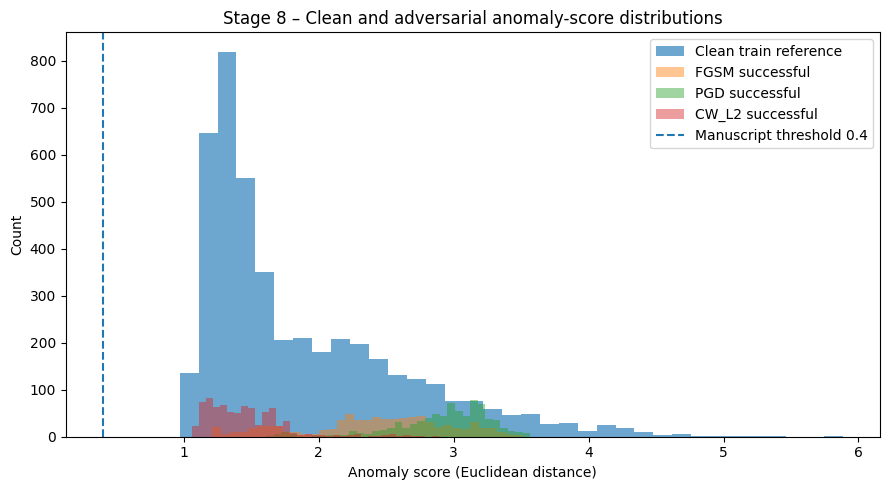

,split,attack,threshold,precision,recall,f1,false_positive_rate
0,validation,FGSM,0.4,0.499687,1.000000,0.666388,1.000000
1,validation,PGD,0.4,0.499687,1.000000,0.666388,1.000000
2,validation,CW_L2,0.4,0.500000,1.000000,0.666667,1.000000
6,validation,FGSM,0.6,0.499687,1.000000,0.666388,1.000000
7,validation,PGD,0.6,0.499687,1.000000,0.666388,1.000000
8,validation,CW_L2,0.6,0.500000,1.000000,0.666667,1.000000
12,validation,FGSM,0.8,0.499687,1.000000,0.666388,1.000000
13,validation,PGD,0.8,0.499687,1.000000,0.666388,1.000000
14,validation,CW_L2,0.8,0.500000,1.000000,0.666667,1.000000
18,validation,FGSM,1.0,0.500628,1.000000,0.667225,0.996241


In [13]:
# Clean training reference and paired clean/attack scores on the test split.
plt.figure(figsize=(9,5))
plt.hist(clean_train_scores, bins=35, alpha=0.65, label="Clean train reference")
for attack in ATTACK_NAMES:
    vals = scores_df[(scores_df.split=="test") & (scores_df.attack==attack) &
                     (scores_df.sample_type=="adversarial") & (scores_df.attack_success==True)]["anomaly_score"].to_numpy()
    if len(vals):
        plt.hist(vals, bins=35, alpha=0.45, label=f"{attack} successful")
plt.axvline(TAU_MANUSCRIPT, linestyle="--", label="Manuscript threshold 0.4")
plt.xlabel("Anomaly score (Euclidean distance)")
plt.ylabel("Count")
plt.title("Stage 8 – Clean and adversarial anomaly-score distributions")
plt.legend()
plt.tight_layout()
plt.show()

threshold_rows = []
for tau in [0.4, 0.6, 0.8, 1.0, 1.2, 1.5, 2.0, 2.5, 3.0]:
    # This is a descriptive sensitivity table, not a test-set threshold-selection procedure.
    for split in ["validation", "test"]:
        for attack in ATTACK_NAMES:
            sub = scores_df[(scores_df.split==split) & (scores_df.attack==attack)]
            clean = sub[sub.sample_type=="clean_paired"]
            adv = sub[(sub.sample_type=="adversarial") & (sub.attack_success==True)]
            if len(adv)==0: continue
            eval_df = pd.concat([clean,adv],ignore_index=True)
            yt = eval_df.true_detection_label.to_numpy(dtype=int)
            yp = (eval_df.anomaly_score.to_numpy() > tau).astype(int)
            threshold_rows.append({
                "split":split,"attack":attack,"threshold":tau,
                "precision":precision_score(yt,yp,zero_division=0),
                "recall":recall_score(yt,yp,zero_division=0),
                "f1":f1_score(yt,yp,zero_division=0),
                "false_positive_rate":float(np.mean(yp[yt==0])) if np.any(yt==0) else np.nan
            })
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df[threshold_df.split=="validation"])


## 14. Save Stage 8 outputs

In [14]:
OUT = Path("/content/Stage8_Adversarial_Detection_Outputs")
OUT.mkdir(parents=True, exist_ok=True)

scores_df.to_csv(OUT/"stage8_anomaly_scores.csv", index=False)
metrics_df.to_csv(OUT/"stage8_detection_metrics_tau_0.4.csv", index=False)
threshold_diagnostic.to_csv(OUT/"stage8_clean_threshold_diagnostic.csv", index=False)
threshold_df.to_csv(OUT/"stage8_threshold_sensitivity_diagnostic.csv", index=False)

config = {
    "stage": 8,
    "method": "DGI-GCN graph embedding centroid-distance anomaly detection",
    "anomaly_score": "Euclidean distance between graph embedding and clean training centroid",
    "centroid_source": "clean Stage 6 training graph embeddings only",
    "manuscript_threshold": float(TAU_MANUSCRIPT),
    "threshold_selection": "fixed manuscript value for diagnostic evaluation; not tuned on test labels",
    "cnn_checkpoint": "Stage 4 best_alzheimer_cnn.pth (frozen)",
    "gcn_checkpoint": "Stage 6 stage6_dgi_gcn_model.pt (frozen)",
    "adversarial_feature_extraction": "Stage 4 CNN embeddings from Stage 7 adversarial images",
    "adversarial_graph_embedding": "frozen-graph one-way extension using cosine kNN to clean graph nodes",
    "knn_k": int(K_NEIGHBORS),
    "stage7_attack_success_flag_used_as_detection_positive": True,
    "failed_attack_attempts_counted_as_positive": False,
    "graph_protocol": "Stage 5/6 transductive clean graph; adversarial nodes attached by frozen one-way extension",
    "seed": SEED,
    "device": str(DEVICE),
    "clean_embedding_reconstruction_max_abs_difference": max_abs_diff
}
with open(OUT/"stage8_config.json","w") as f:
    json.dump(config,f,indent=2)

zip_path = "/content/Stage8_Adversarial_Detection_Outputs.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob("*"):
        if p.is_file():
            zf.write(p,arcname=p.name)

print("Created:", zip_path)
print("Output files:", [p.name for p in OUT.iterdir()])
files.download(zip_path)


Created: /content/Stage8_Adversarial_Detection_Outputs.zip
Output files: ['stage8_threshold_sensitivity_diagnostic.csv', 'stage8_detection_metrics_tau_0.4.csv', 'stage8_clean_threshold_diagnostic.csv', 'stage8_config.json', 'stage8_anomaly_scores.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. What to upload back for validation

After the notebook finishes, upload `Stage8_Adversarial_Detection_Outputs.zip` here.

I will check:
- Whether the Stage 6 graph embeddings were reconstructed correctly.
- Whether all Stage 7 splits and attack arrays were loaded with the right indices.
- Whether adversarial embeddings are finite and 128-dimensional.
- Whether the clean centroid uses training nodes only.
- Whether the manuscript threshold 0.4 produces sensible clean false-positive behaviour.
- Whether detection metrics are computed only on successful attack examples and their paired clean samples.

**Important:** Do not update manuscript tables with expected or previously stated detection scores. Use only the results produced by this run. If the 0.4 threshold is incompatible with the measured embedding scale, we will document and resolve that before final evaluation.
